# ASDS-5302 Final Project - Humberto Alanis - Daniel Ramirez - Summer 2026  

## Project Scope:
In this project we will be analyzing the "Polish Companies Bankruptcy" dataset and build a machine learning classification model to predict whether a company will file for bankruptcy.

## Project Background:
Business bankruptcy is the legal process in which a business in crippling debt restructures their assets and organization such that their business is provided a chance of relief. In other words businesses in debt are given oppotunities from the government to pay it back.

## Project Description:
The dataset was found on the UC Irvine Machine Learning Repository and would be collected from the Emerging Markets Information Service (EMIS). The data collected contains bankrupt companies analyzed from 2000-2012 and operating companies from 2007-2012. Then the data was classified into 5 different classification data sets that depended on the forecasting period (length of time into the future we are predicting).
e.g. 
- 1stYear â€“ the data contains financial rates from 1st year of the forecasting period and corresponding class label that indicates bankruptcy status after 5 years. The data contains 7027 instances (financial statements), 271 represents bankrupted companies, 6756 firms that did not bankrupt in the forecasting period.
- 2ndYear â€“ the data contains financial rates from 2nd year of the forecasting period and corresponding class label that indicates bankruptcy status after 4 years. The data contains 10173 instances (financial statements), 400 represents bankrupted companies, 9773 firms that did not bankrupt in the forecasting period.
- 3rdYear â€“ the data contains financial rates from 3rd year of the forecasting period and corresponding class label that indicates bankruptcy status after 3 years. The data contains 10503 instances (financial statements), 495 represents bankrupted companies, 10008 firms that did not bankrupt in the forecasting period.
- 4thYear â€“ the data contains financial rates from 4th year of the forecasting period and corresponding class label that indicates bankruptcy status after 2 years. The data contains 9792 instances (financial statements), 515 represents bankrupted companies, 9277 firms that did not bankrupt in the forecasting period.
- 5thYear â€“ the data contains financial rates from 5th year of the forecasting period and corresponding class label that indicates bankruptcy status after 1 year. The data contains 5910 instances (financial statements), 410 represents bankrupted companies, 5500 firms that did not bankrupt in the forecasting period.

We chose to study the "3rdYear" dataset as it had the most instances, and the classification label would have an appropriate forecasting period of three years. This three years would be a reasonable amount of time for companies to be warned about their possible bankruptcy risk.

## Project Variables:
- X1	net profit / total assets
- X2	total liabilities / total assets
- X3	working capital / total assets
- X4	current assets / short-term liabilities
- X5	[(cash + short-term securities + receivables - short-term liabilities) / (operating expenses - depreciation)] * 365
- X6	retained earnings / total assets
- X7	EBIT / total assets
- X8	book value of equity / total liabilities
- X9	sales / total assets
- X10	equity / total assets
- X11	(gross profit + extraordinary items + financial expenses) / total assets
- X12	gross profit / short-term liabilities
- X13	(gross profit + depreciation) / sales
- X14	(gross profit + interest) / total assets
- X15	(total liabilities * 365) / (gross profit + depreciation)
- X16	(gross profit + depreciation) / total liabilities
- X17	total assets / total liabilities
- X18	gross profit / total assets
- X19	gross profit / sales
- X20	(inventory * 365) / sales
- X21	sales (n) / sales (n-1)
- X22	profit on operating activities / total assets
- X23	net profit / sales
- X24	gross profit (in 3 years) / total assets
- X25	(equity - share capital) / total assets
- X26	(net profit + depreciation) / total liabilities
- X27	profit on operating activities / financial expenses
- X28	working capital / fixed assets
- X29	logarithm of total assets
- X30	(total liabilities - cash) / sales
- X31	(gross profit + interest) / sales
- X32	(current liabilities * 365) / cost of products sold
- X33	operating expenses / short-term liabilities
- X34	operating expenses / total liabilities
- X35	profit on sales / total assets
- X36	total sales / total assets
- X37	(current assets - inventories) / long-term liabilities
- X38	constant capital / total assets
- X39	profit on sales / sales
- X40	(current assets - inventory - receivables) / short-term liabilities
- X41	total liabilities / ((profit on operating activities + depreciation) * (12/365))
- X42	profit on operating activities / sales
- X43	rotation receivables + inventory turnover in days
- X44	(receivables * 365) / sales
- X45	net profit / inventory
- X46	(current assets - inventory) / short-term liabilities
- X47	(inventory * 365) / cost of products sold
- X48	EBITDA (profit on operating activities - depreciation) / total assets
- X49	EBITDA (profit on operating activities - depreciation) / sales
- X50	current assets / total liabilities
- X51	short-term liabilities / total assets
- X52	(short-term liabilities * 365) / cost of products sold)
- X53	equity / fixed assets
- X54	constant capital / fixed assets
- X55	working capital
- X56	(sales - cost of products sold) / sales
- X57	(current assets - inventory - short-term liabilities) / (sales - gross profit - depreciation)
- X58	total costs /total sales
- X59	long-term liabilities / equity
- X60	sales / inventory
- X61	sales / receivables
- X62	(short-term liabilities *365) / sales
- X63	sales / short-term liabilities
- X64	sales / fixed assets

## Extra Definitions:
- Liquidity:
    - Liquidity means how fast and easy you can turn an asset into cash without changing its price. Cash is the most liquid thing you can own, while things like houses or art are very hard to sell quickly.
- Current Assets:
    - Short-term resources like cash, marketable securities, and receivables expected to convert to cash within a year.
- Inventories:
    - Goods or materials held for sale or production, also less liquid than cash.
- Quick Assets:
    - (current assets - inventories) is also known as the quick assets or the numerator of the Quick Ratio. Highly liquid current assets that can be converted into cash within 90 days without losing value. 
- Long-Term Liabilities:
    - Financial obligations and debts due after twelve months (such as bonds or multi-year bank loans).

## Libraries Used

In [21]:
import numpy as np
import io 
import zipfile
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

## Downloading File from UCI

In [3]:
url = "https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip"
response = requests.get(url)
zip_file = zipfile.ZipFile(io.BytesIO(response.content))

In [4]:
data3, _ = arff.loadarff(io.TextIOWrapper(zip_file.open('3year.arff')))
df = pd.DataFrame(data3)

In [5]:
df3 = df.copy()

In [6]:
df3['class'] = df3['class'].astype(int)

In [7]:
df3

,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,...,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,class
0,0.174190,0.41299,0.143710,1.34800,-28.9820,0.603830,0.219460,1.122500,1.19610,0.463590,...,0.163960,0.375740,0.83604,0.000007,9.7145,6.2813,84.291,4.3303,4.0341,0
1,0.146240,0.46038,0.282300,1.62940,2.5952,0.000000,0.171850,1.172100,1.60180,0.539620,...,0.027516,0.271000,0.90108,0.000000,5.9882,4.1103,102.190,3.5716,5.9500,0
2,0.000595,0.22612,0.488390,3.15990,84.8740,0.191140,0.004572,2.988100,1.00770,0.675660,...,0.007639,0.000881,0.99236,0.000000,6.7742,3.7922,64.846,5.6287,4.4581,0
3,0.024526,0.43236,0.275460,1.78330,-10.1050,0.569440,0.024526,1.305700,1.05090,0.564530,...,0.048398,0.043445,0.95160,0.142980,4.2286,5.0528,98.783,3.6950,3.4844,0
4,0.188290,0.41504,0.342310,1.92790,-58.2740,0.000000,0.233580,1.409400,1.33930,0.584960,...,0.176480,0.321880,0.82635,0.073039,2.5912,7.0756,100.540,3.6303,4.6375,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10498,0.002861,0.58067,-0.223860,0.51658,-31.8660,0.002861,0.002861,0.618550,1.01200,0.359170,...,0.011834,0.007966,0.98817,0.327360,38.1420,39.1500,42.202,8.6489,5.2646,1
10499,-0.051968,0.55254,0.147150,2.16980,12.7480,-0.051968,-0.034361,0.669830,0.94694,0.370110,...,-0.056037,-0.140410,1.05600,1.153000,14.4930,9.2851,32.761,11.1410,1.9276,1
10500,-0.135900,0.83954,-0.342010,0.46526,-145.3100,-0.219120,-0.131860,0.191130,1.09990,0.160460,...,0.144120,-0.846930,0.85427,0.814200,6.2737,9.6966,212.230,1.7198,1.5659,1
10501,0.009423,0.50028,0.261630,1.52300,-10.1580,0.009423,0.007700,0.989900,1.01230,0.495230,...,0.012186,0.019027,0.98781,0.000000,5.9675,4.3536,98.240,3.7154,7.8068,1


### Using just 3year.arff
 We decided to just use 3years rather than merging all 5 years in a dataframe. We had multiple reasons as to why it was simpler and safer than combining them.

- Since we are using only 3year our target variable will have a specific target. We will be predicting if a company will go bankrupt in 3 years rather than a span of 1-5 years if we merged the data.

- Using just 3year will mean that we will have zero data leakage. Having only one dataset means that every row represents a disctinctive company for that periods. We wont have to worry about the same company appearing in the training set and the test set.

- Now that we are only using one it is much easier to deal with the data, making it easier to interpret the results.


## Exploratory Data Analysis

### Global Dataframe Info

In [8]:
df3.shape

(10503, 65)

In [34]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10503 entries, 0 to 10502
Data columns (total 65 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Attr1   10503 non-null  float64
 1   Attr2   10503 non-null  float64
 2   Attr3   10503 non-null  float64
 3   Attr4   10485 non-null  float64
 4   Attr5   10478 non-null  float64
 5   Attr6   10503 non-null  float64
 6   Attr7   10503 non-null  float64
 7   Attr8   10489 non-null  float64
 8   Attr9   10500 non-null  float64
 9   Attr10  10503 non-null  float64
 10  Attr11  10503 non-null  float64
 11  Attr12  10485 non-null  float64
 12  Attr13  10460 non-null  float64
 13  Attr14  10503 non-null  float64
 14  Attr15  10495 non-null  float64
 15  Attr16  10489 non-null  float64
 16  Attr17  10489 non-null  float64
 17  Attr18  10503 non-null  float64
 18  Attr19  10460 non-null  float64
 19  Attr20  10460 non-null  float64
 20  Attr21  9696 non-null   float64
 21  Attr22  10503 non-null  float64
 22

In [15]:
df3.dtypes

Attr1     float64
Attr2     float64
Attr3     float64
Attr4     float64
Attr5     float64
           ...   
Attr61    float64
Attr62    float64
Attr63    float64
Attr64    float64
class       int64
Length: 65, dtype: object

#### Data Types:
We can confidently state that the entire dataset is comprised of numerical entries with our label being the only integer. 

In [35]:
df3.describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
Attr1,10503.0,0.053,0.648,-1.769200e+01,0.001,0.043,0.124,52.652
Attr2,10503.0,0.620,6.427,0.000000e+00,0.254,0.464,0.689,480.730
Attr3,10503.0,0.095,6.420,-4.797300e+02,0.017,0.199,0.420,17.708
Attr4,10485.0,9.980,523.692,2.000000e-03,1.040,1.606,2.960,53433.000
Attr5,10478.0,-1347.662,118580.569,-1.190300e+07,-52.071,1.579,56.084,685440.000
...,...,...,...,...,...,...,...,...
Attr61,10486.0,13.935,83.704,-6.590000e+00,4.486,6.677,10.587,4470.400
Attr62,10460.0,135.537,25991.162,-2.336500e+06,40.737,70.664,118.220,1073500.000
Attr63,10485.0,9.095,31.419,-0.000000e+00,3.063,5.139,8.883,1974.500
Attr64,10275.0,35.767,428.298,-0.000000e+00,2.023,4.059,9.683,21499.000


#### Global Statistics:
From looking at the statistics of our first/last four features we can confirm that our dataset is heavily skewed. The mean of "Attr5" ([(cash + short-term securities + receivables - short-term liabilities) / (operating expenses - depreciation)] * 365) is -1,347.66 with a standard deviation of 118,580.56, in other words the spread of data in the feature is very large. "Att62" (short-term liabilities *365) / sales) would also have a high standard deviation at 25,991.16.

### Detecting Global Missing Values

In [13]:
total_rows = len(df3)
missing_per_col = df3.isnull().sum()
missing_percent = (missing_per_col / total_rows) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_per_col,
    'Missing Percent': missing_percent
})
missing_summary = missing_summary[missing_summary['Missing Count'] > 0].sort_values(by = 'Missing Count', ascending = False)

In [14]:
missing_summary

,Missing Count,Missing Percent
Attr37,4736,45.091879
Attr21,807,7.683519
Attr27,715,6.807579
Attr60,592,5.636485
Attr45,591,5.626964
Attr28,228,2.170808
Attr54,228,2.170808
Attr53,228,2.170808
Attr64,228,2.170808
Attr24,227,2.161287


In [15]:
# Humberto will add Missingno Plot

#### Missing Value Percentage:
Attribute 37 would have 47.10% missing values, the highest of the entire dataset. This variable is defines as "(current assets - inventories) / long-term liabilities". This variable is indicative of a businesses long-term liquidity as it tells us the ratio of a businesses highly liquid current assets with its long term debts. In other words it measures how effectively a company can back up its long-term debt obligations using its most readily available, liquid short-term resources.

Because our data is so skewed we will impute null values with their respective median.

### Checking For Global Outliers 

In [37]:
df3_no_label = df3.drop(columns = ['class'])

Q1 = df3_no_label.quantile(0.25)
Q3 = df3_no_label.quantile(0.75)
IQR = Q3 - Q1

outliers_matrix = (df3_no_label < (Q1 - 1.5 * IQR)) | (df3_no_label > (Q3 + 1.5 * IQR))

outliers_summary = pd.DataFrame({
    'Outlier Count': outliers_matrix.sum(),
    'Outlier Percent': (outliers_matrix.sum() / total_rows) * 100
}).sort_values(by = 'Outlier Count', ascending = False)

In [38]:
outliers_summary

,Outlier Count,Outlier Percent
Attr6,3170,30.181853
Attr27,2158,20.546511
Attr15,1799,17.128439
Attr55,1796,17.099876
Attr41,1777,16.918976
...,...,...
Attr38,325,3.094354
Attr10,305,2.903932
Attr2,290,2.761116
Attr3,271,2.580215


#### Outlier Percentage:
The variable with the most outliers would be Attribute 6 with 30.20%. Attribute 6 can be defined as the "retained earnings / total assets". The retained earnings to total assets ratio measures a company's cumulative profitability. It indicates how much of a firm's assets were funded by its own historical profits rather than debt. A higher ratio signals financial strength, while a lower ratio points to a heavier reliance on borrowed funds.

In [50]:
skew = df3_no_label.skew()
skew

Attr1      51.971750
Attr2      71.596019
Attr3     -71.691576
Attr4     101.305786
Attr5     -96.857582
             ...    
Attr60     96.550112
Attr61     37.139765
Attr62    -61.737752
Attr63     36.053408
Attr64     31.967754
Length: 64, dtype: float64

In [51]:
skew.describe()

count     64.000000
mean      30.693364
std       61.020925
min     -100.559207
25%      -13.168418
50%       50.888170
75%       72.628505
max      101.930966
dtype: float64

#### Global Skewness:
From looking at the first/last 4 features calculated skewness we gain mathematical proof of our data being skewed. The pandas ".skew()" function computes the unbiased skewness of our data across the whole dataframe. Any value close to zero would mean the feature is distributes symmetrically, any value greater than zero is right-skewed and any value less than zero would be considered left-skewed. Here most of our values are clearly greater than or less than zero. Our smallest skew value is at -100.55 and our max would be 101.93, and we also have a mean at 30.69. Meaning we are dealing with extremely skewed data.

In [54]:
# More visualiztions of outliers and skewness

### Check Global Class Imbalance

In [22]:
class_counts = df3['class'].value_counts()
class_percentages = df3['class'].value_counts(normalize = True) * 100

imbalance_summary = pd.DataFrame({'Count': class_counts, 'Percentage': class_percentages.round(2)})

In [59]:
imbalance_summary

,Count,Percentage
class,,
0,10008,95.29
1,495,4.71


In [55]:
# Same here

#### Global Class Imbalance:
Our label feature, (whether or not a company files for bankruptcy in three years) would have a severe imbalance in classes. We have binary labels "0" a company doesn't go bankrupt, and "1" a company does go bankrupt. Observing the counts we can clearly tell there is a class imbalance in our data, so we must accomodate our models accordingly.

### Checking Global Collinearity and Correlation

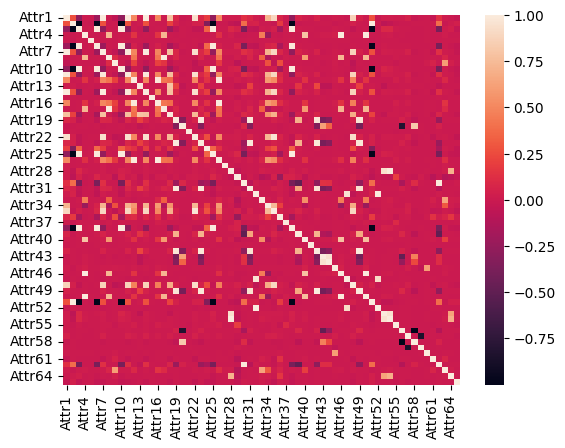

In [18]:
corr_matrix = df3.corr()
sns.heatmap(corr_matrix)
plt.show()

In [68]:
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [ ]:
high_corr = [column for column in upper_tri.columns if any(upper_tri[column].abs() > 0.8)]

In [69]:
for col in upper_tri.columns:
    correlated_features = upper_tri.index[upper_tri[col].abs() > 0.8].tolist()
    for row in correlated_features:
        correlation_value = upper_tri.loc[row, col]
        print(f"'{row}' and '{col}' are highly correlated: {correlation_value:.3f}")

'Attr2' and 'Attr3' are highly correlated: -0.998
'Attr2' and 'Attr6' are highly correlated: -0.986
'Attr3' and 'Attr6' are highly correlated: 0.985
'Attr1' and 'Attr7' are highly correlated: 0.999
'Attr2' and 'Attr10' are highly correlated: -1.000
'Attr3' and 'Attr10' are highly correlated: 0.998
'Attr6' and 'Attr10' are highly correlated: 0.986
'Attr1' and 'Attr11' are highly correlated: 0.989
'Attr7' and 'Attr11' are highly correlated: 0.991
'Attr1' and 'Attr14' are highly correlated: 0.999
'Attr7' and 'Attr14' are highly correlated: 1.000
'Attr11' and 'Attr14' are highly correlated: 0.991
'Attr12' and 'Attr16' are highly correlated: 0.989
'Attr8' and 'Attr17' are highly correlated: 0.999
'Attr1' and 'Attr22' are highly correlated: 0.942
'Attr7' and 'Attr22' are highly correlated: 0.945
'Attr11' and 'Attr22' are highly correlated: 0.942
'Attr14' and 'Attr22' are highly correlated: 0.945
'Attr19' and 'Attr23' are highly correlated: 0.999
'Attr2' and 'Attr25' are highly correlated: -0

#### Global Collinearity and Correlation:
Here we inspect the correlation heatmap of our entire data set to gain a broad sense of how our features relate with eachother. From looking at the heatmap we can see that there is plenty of independent features, but there are also some that are highly correlated. The white and black spots would identify the highly correlated features and differentiate the positive and negative correlation respectively. We even specifically analyze the features that share a correlation coefficient greater than the 0.8. When analyzing the correlated features we can see that many of them calculate the same data. Like "Attr2", "Attr3" and "Attr6", which are "total liabilities / total assets", "working capital / total assets", and "retained earnings / total assets". Notice the same denominator. 

## Data Preprocessing and Partitioning

### Splitting our Dataset

In [45]:
X = df3.drop(columns = ["class"])
y = df3["class"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2004,stratify=y)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (8402, 64)
Testing features shape: (2101, 64)


#### Stratifying our Test subset
When we use the "train_test_split" function from sklearn we have the option of stratifying our randomized subsets. We stratify our split because label is severly inbalanced, with companies that are not predicted to file bankruptcy in 3 years to be 95%. Companies expected to file for bankruptcy in 3 years fill ~5% of our dataset.

### Imputation of Null Values

In [56]:
imputer = SimpleImputer(strategy='median',add_indicator=True)

X_train_raw = imputer.fit_transform(X_train)

new_cols_name = imputer.get_feature_names_out(X_train.columns)

X_train_imputed = pd.DataFrame(X_train_raw, columns=new_cols_name)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=new_cols_name)

In [57]:
X_train_imputed.isnull().sum()

Attr1                      0
Attr2                      0
Attr3                      0
Attr4                      0
Attr5                      0
                          ..
missingindicator_Attr60    0
missingindicator_Attr61    0
missingindicator_Attr62    0
missingindicator_Attr63    0
missingindicator_Attr64    0
Length: 108, dtype: int64

In [58]:
X_test_imputed.isnull().sum()

Attr1                      0
Attr2                      0
Attr3                      0
Attr4                      0
Attr5                      0
                          ..
missingindicator_Attr60    0
missingindicator_Attr61    0
missingindicator_Attr62    0
missingindicator_Attr63    0
missingindicator_Attr64    0
Length: 108, dtype: int64